<a href="https://colab.research.google.com/github/TrishaPal2003/Bank_Authentication/blob/main/Banknote_Authentication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Banknote Authentication Using KNN and SVM

**Team Name:** Silence

**Project Type:** Binary Classification

**Dataset:** UCI Banknote Authentication Dataset

**Algorithms:** K-Nearest Neighbors (KNN) and Support Vector Machine (SVM)

**Objective:** To build and compare two machine learning classification models that distinguish genuine banknotes from forged banknotes using four numerical features extracted from banknote images.

**Team Members:**
- Name : Tamanna Akter (ID: 111223057)
- Name : Trisha Pal (ID: 111223058)

**Course:**  Machine Learning



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
columns = ["varience", "skewness", "curtosis", "entropy", "class"]
df = pd.read_csv("data_banknote_authentication.csv",header=None, names=columns)
print(df.head())
print(df.shape)
print(df.info())
print(df.columns)
print(df.isnull().sum())
print(df.duplicated().sum())
print(df['class'].value_counts())
print(df.describe())

   varience  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0
(1372, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   varience  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB
None
Index(['varience', 'skewness', 'curtosis', 'entropy', 'class'], dtype='object')
varience    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64
24
class
0    762
1    610
Name: count, dtype: int64
          varience     skewness     curtosis      e

## Exploratory Data Analysis (EDA)

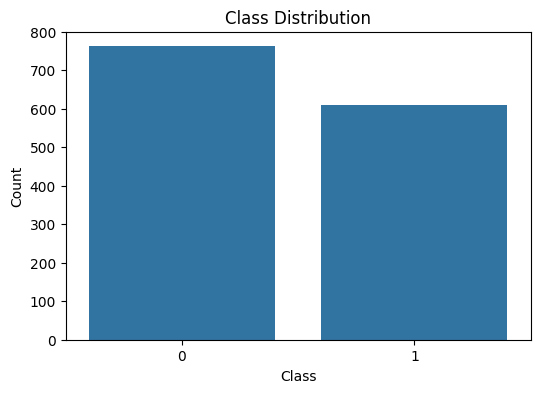

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x='class', data=df)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

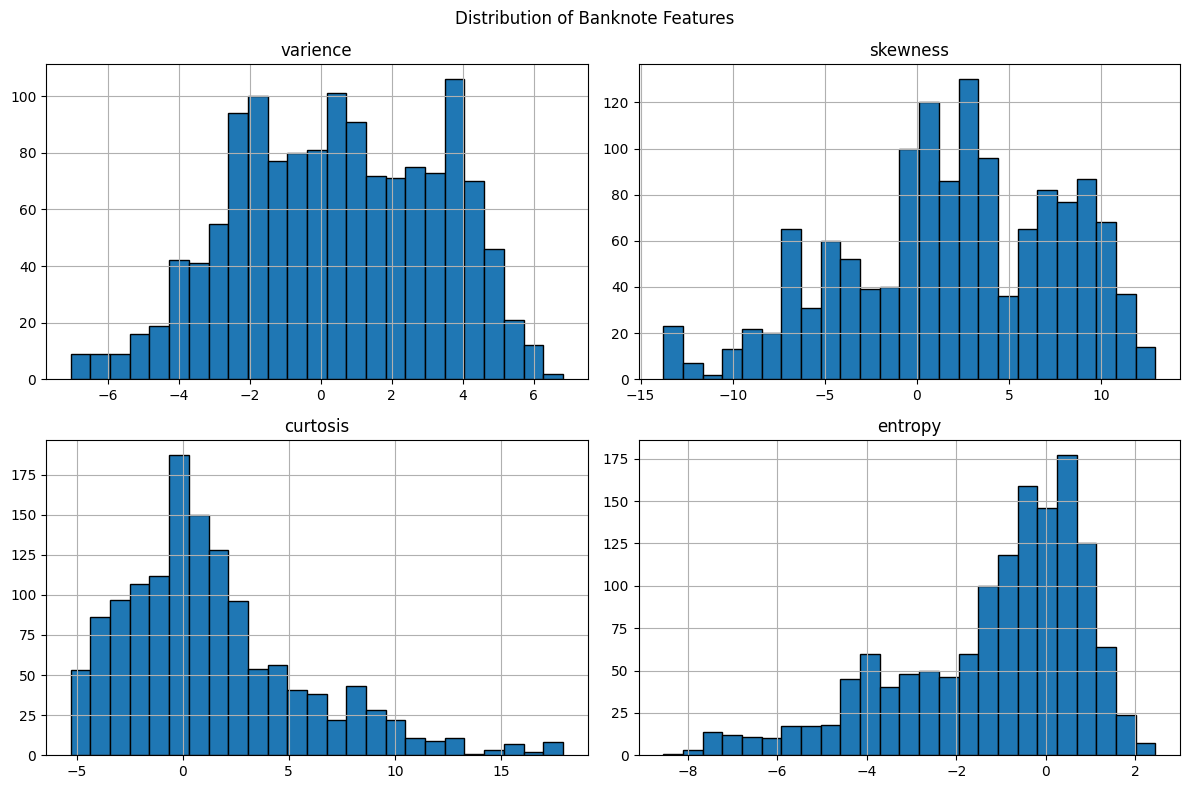

In [ ]:
features = df.drop('class', axis=1)
target = df['class']
features.hist(figsize=(12, 8), bins=25, edgecolor='black')
plt.suptitle("Distribution of Banknote Features")
plt.tight_layout()
plt.show()

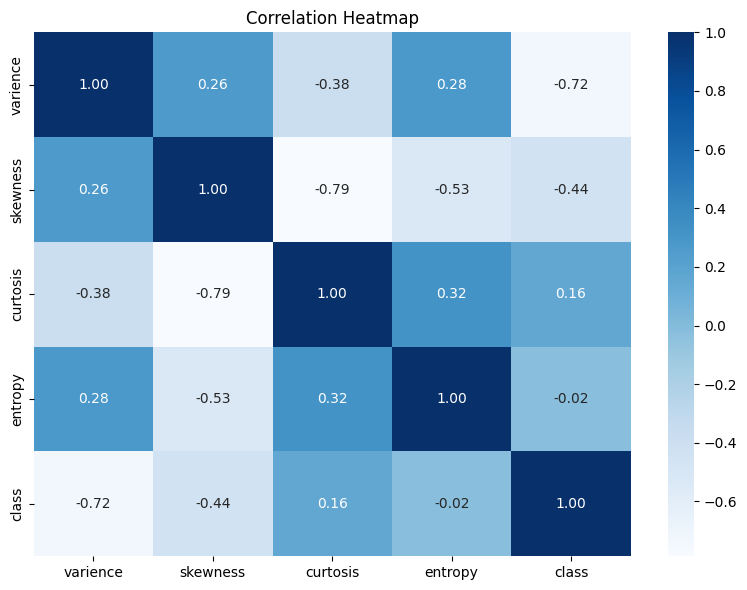

In [ ]:
plt.figure(figsize=(8, 6))
correlation = df.corr()
sns.heatmap(correlation, annot=True, cmap='Blues', fmt='.2f')
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

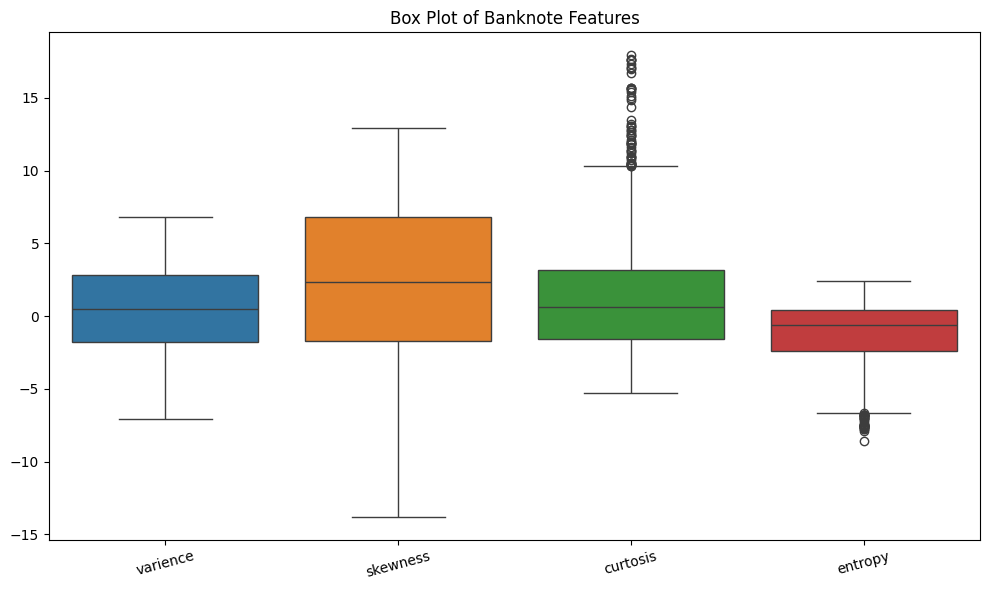

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=features)
plt.title("Box Plot of Banknote Features")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# EDA Oservation:
The class distribution was examined to understand the number of observation in each target class. Histograms were used to study the distribution of the four numerical features. A correlation heatmap was generated to investigate linear reationships between the features and the target variable.

In [ ]:
print(f"Features Shape:", features.shape)
print(f"Target Shape:", target.shape)

Features Shape: (1372, 4)
Target Shape: (1372,)


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(features, target, test_size=0.20, random_state=42, stratify=target)


In [ ]:
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

knn_pipeline.fit(x_train, y_train)
knn_predictions = knn_pipeline.predict(x_test)


In [ ]:
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(kernel='rbf'))
])
svm_pipeline.fit(x_train, y_train)
svm_predictions = svm_pipeline.predict(x_test)

In [ ]:
knn_accuracy = accuracy_score(y_test, knn_predictions)
svm_accuracy = accuracy_score(y_test, svm_predictions)

print(f"K-Nearest Neighbors Accuracy: {knn_accuracy}")
print(f"Support Vector Machine Accuracy: {svm_accuracy}")

K-Nearest Neighbors Accuracy: 1.0
Support Vector Machine Accuracy: 1.0


In [ ]:
print(f"KNN Classification Report:", classification_report(y_test, knn_predictions))
print(f"SVM Classification Report:", classification_report(y_test, svm_predictions))

KNN Classification Report:               precision    recall  f1-score   support

           0       1.00      1.00      1.00       153
           1       1.00      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275

SVM Classification Report:               precision    recall  f1-score   support

           0       1.00      1.00      1.00       153
           1       1.00      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275

